# 03 – FX revenue, FX shocks and FX debt (Branch 1: From local to global)

**Hypothesis:**
> **H1 (Branch 1):** The high share of export sales protected the gross margin during FX shocks (2018, 2021–22). However, because FX debt also rose during the transformation, this protection may have been partly offset on the balance sheet. Test: margin in shock periods; coverage of FX debt by FX revenue.

**Data:** Only `annual_master.csv`, `fx_debt_annual.csv`, `quarterly_series.csv`, `fx_rates_annual.csv`, `financials_annual.csv` under `output/tables/`. No PDFs are read.

**Decisions:**
- **Two debt views:**
  - *Group view (main):* All FX loans (EUR + USD + other, excluding leases) are compared with export sales and the EBITDA proxy.
  - *Turkey view (supplementary):* Net FX position from the FX table and 10% FX sensitivity. This table covers only companies with TRY functional currency; subsidiaries abroad are excluded.
- **Two exceptions to the own-report rule** (because of internal inconsistencies in the report):
  - 2018 net FX position → comparative value in the 2019 report.
  - 2023 derivatives and net position → comparative value in the 2024 report.
- **FX conversion:**
  - Balance sheet items (debt, position): EVDS year-end rate in both series.
  - Income items: annual average in nominal years, year-end rate in IAS 29 years.

## Setup: loading data and helpers

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "output" / "tables"
FIGS = ROOT / "output" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
C_GREY, C_INK, C_MUTED = "#8a8985", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False,
})
YEARS = list(range(2016, 2026))

In [2]:
master = pd.read_csv(TABLES / "annual_master.csv")
own = master[(master["view"] == "own") & master["year"].between(2016, 2025)].set_index("year").sort_index()
fxd = pd.read_csv(TABLES / "fx_debt_annual.csv")
fxd["report_year"] = fxd["source_file"].str.extract(r"(\d{4})_12", expand=False).astype(int)
quarterly = pd.read_csv(TABLES / "quarterly_series.csv")
rates = pd.read_csv(TABLES / "fx_rates_annual.csv")

usd_end = rates[(rates["item"] == "fx_usd_try_period_end") & (rates["period"] == "FY")].set_index("year")["value"]

def fxv(item, year, report_year=None):
    """Single value from fx_debt_annual; default: the year's own report."""
    r = fxd[(fxd["item"] == item) & (fxd["year"] == year) & (fxd["report_year"] == (report_year or year))]
    return r["value"].iloc[0] if len(r) else np.nan

print(f"annual_master own: {len(own)} years; fx_debt_annual: {len(fxd)} rows; quarterly series: {quarterly['year'].min()}–{quarterly['year'].max()}")

annual_master own: 10 years; fx_debt_annual: 832 rows; quarterly series: 2016–2023


## 1. FX revenue share (2016–2025)

`export_share` = export sales / (domestic + export sales), on gross sales before deductions (revenue note).

**Scope note:**
- **2016–2023:** Export sales are mainly exports from Turkey. In 2021–2022 they also include sales to the related party SBS (2022: TRY 1.62 billion).
- **After 2024:** Sales of subsidiaries abroad (SBS, Mannok) are also included. From 2024 the "exports" in the FX note and the "export sales" in the revenue note diverge (2024: TRY 8.2 vs 16.8 billion).

The share after 2024 should therefore be read as "the non-Turkey part of group revenue", not as "the share of exports from Turkey".

In [3]:
r2022 = master[(master["year"] == 2022) & (master["view"] == "restated_in_2023")].iloc[0]
export_tbl = pd.DataFrame({
    "basis": own["basis"],
    "revenue_export_mn_try": own["revenue_export"] / 1e6,
    "revenue_domestic_mn_try": own["revenue_domestic"] / 1e6,
    "export_share_pct": own["export_share"] * 100,
    "revenue_export_mn_usd": own["revenue_export"] / own["usd_try_rate_used"] / 1e6,
    "usd_rate_basis": own["usd_rate_basis"],
})
print(f"2022 (2023 report, IAS 29 + SBS) export_share: {r2022['export_share']*100:.1f}%")
export_tbl.round(1)

2022 (2023 report, IAS 29 + SBS) export_share: 44.5%


,basis,revenue_export_mn_try,revenue_domestic_mn_try,export_share_pct,revenue_export_mn_usd,usd_rate_basis
year,,,,,,
2016,nominal,396.0,878.2,31.1,131.1,EVDS USD/TRY 2016 annual average
2017,nominal,561.2,1092.2,33.9,154.0,EVDS USD/TRY 2017 annual average
2018,nominal,869.4,1081.0,44.6,181.0,EVDS USD/TRY 2018 annual average
2019,nominal,1146.9,860.8,57.1,202.2,EVDS USD/TRY 2019 annual average
2020,nominal,1150.9,1203.5,48.9,164.2,EVDS USD/TRY 2020 annual average
2021,nominal,2304.6,1794.1,56.2,259.4,EVDS USD/TRY 2021 annual average
2022,nominal,4757.2,4849.4,49.5,287.2,EVDS USD/TRY 2022 annual average
2023,tms29,8638.7,13477.6,39.1,293.9,EVDS USD/TRY 2023 year-end (IAS 29: purchasing...
2024,tms29,16817.6,14039.8,54.5,477.5,EVDS USD/TRY 2024 year-end (IAS 29: purchasing...


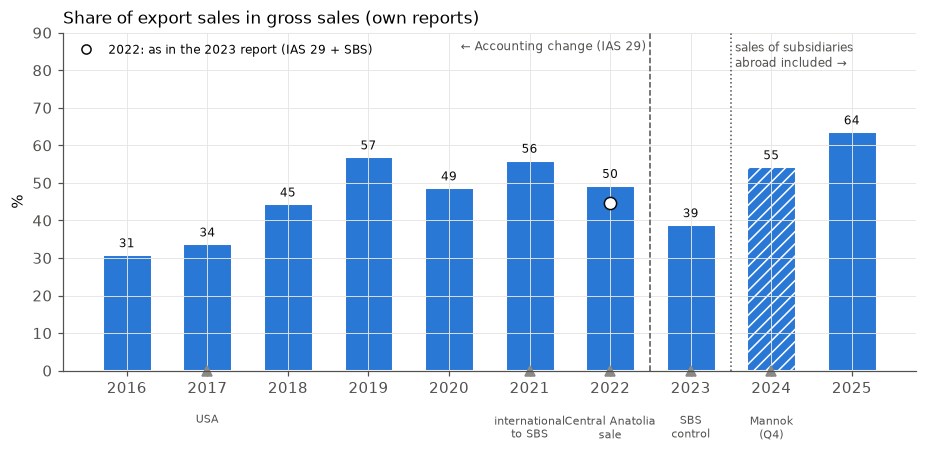

In [4]:
SCOPE = [(2017, "USA"), (2021, "international\nto SBS"), (2022, "Central Anatolia\nsale"), (2023, "SBS\ncontrol"), (2024, "Mannok\n(Q4)")]
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(YEARS, export_tbl["export_share_pct"], width=0.62, color=C_BLUE, edgecolor="white", linewidth=2)
bars[YEARS.index(2024)].set_hatch("///")  # 2024: Mannok only Q4 (scope label at the bottom)
for y, v in export_tbl["export_share_pct"].items():
    ax.text(y, v + 1, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=C_INK)
ax.plot(2022, r2022["export_share"] * 100, marker="o", markersize=8, markerfacecolor="white", markeredgecolor=C_INK, linestyle="none")
ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
ax.text(2022.45, 88, "← Accounting change (IAS 29)", fontsize=8, color=C_MUTED, va="top", ha="right")
ax.axvline(2023.5, color=C_MUTED, linestyle=":", linewidth=1)
ax.text(2023.55, 88, "sales of subsidiaries\nabroad included →", fontsize=8, color=C_MUTED, va="top")
for y, t in SCOPE:
    ax.plot(y, 0.0, marker="^", markersize=7, color=C_GREY, transform=ax.get_xaxis_transform(), clip_on=False)
    ax.text(y, -0.13, t, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7, color=C_MUTED)
ax.set_xticks(YEARS)
ax.set_ylim(0, 90)
ax.set_ylabel("%")
ax.set_title("Share of export sales in gross sales (own reports)", loc="left", fontsize=11)
ax.legend(handles=[Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor=C_INK, linestyle="none",
                          label="2022: as in the 2023 report (IAS 29 + SBS)")], loc="upper left", fontsize=8)
fig.subplots_adjust(bottom=0.24)
fig.savefig(FIGS / "03_export_share.png", bbox_inches="tight")
plt.show()

**What we see:** The export sales share is 31% in 2016, 45–57% in 2018–2021, 50% in 2022, 39% in 2023 and 64% in 2025. The 2018 and 2021–22 FX shocks fall into a period when the share was 45–57%. The increase in 2024–2025 comes together with the inclusion of sales of subsidiaries abroad; because of the definition difference it is not directly comparable with earlier years.

## 2. Quarterly gross margin during FX shocks

- **Margin:** `quarterly_series.csv`, `gross_margin`, column `value_preferred`. This column is used for pattern and shock-timing analyses.
- **Coverage:** The quarterly series covers only the nominal period (2016 Q1 – 2023 Q3).
- **FX:** Change in the quarterly average USD/TRY rate versus the previous quarter (EVDS).
- **Shock quarter definition:** A quarter in which the average rate rose by at least 20% versus the previous quarter. This criterion selects 2018 Q3, 2021 Q4, 2022 Q1 and 2023 Q3; the last one is outside the shocks named in H1 but is shown in the table.
- **Post-shock quarter:** Because the margin effect may be delayed, the quarter after the shock quarter is also shown.
- **Seasonality:** Because cement sales are seasonal, the margin change is given against three benchmarks: the previous quarter, the same quarter of the previous year and the average of the previous four quarters.
- **Data limit:** There is no quarterly FX revenue share; the domestic/export breakdown of the revenue note was only extracted annually. This section reads the margin in shock quarters in the context of the annual FX revenue share.

In [5]:
gm = quarterly[quarterly["item"] == "gross_margin"][["year", "period", "value_preferred"]].rename(columns={"value_preferred": "gross_margin"})
qfx = rates[(rates["item"] == "fx_usd_try_average") & rates["period"].str.startswith("Q")][["year", "period", "value"]]
qfx = qfx.rename(columns={"value": "usd_try_avg"})
qdf = qfx.merge(gm, on=["year", "period"], how="left").sort_values(["year", "period"]).reset_index(drop=True)
qdf["usd_try_qoq_pct"] = qdf["usd_try_avg"].pct_change() * 100
qdf = qdf[qdf["year"].between(2016, 2023) & ~((qdf["year"] == 2023) & (qdf["period"] == "Q4"))].reset_index(drop=True)
qdf["label"] = qdf["year"].astype(str) + " " + qdf["period"]
qdf["gm_pct"] = qdf["gross_margin"] * 100
qdf["d_qoq"] = qdf["gm_pct"].diff()
qdf["d_yoy"] = qdf["gm_pct"] - qdf["gm_pct"].shift(4)
qdf["d_vs_prev4"] = qdf["gm_pct"] - qdf["gm_pct"].shift(1).rolling(4).mean()
qdf["shock"] = qdf["usd_try_qoq_pct"] >= 20
print("Shock quarters:", ", ".join(qdf.loc[qdf["shock"], "label"]))

Shock quarters: 2018 Q3, 2021 Q4, 2022 Q1, 2023 Q3


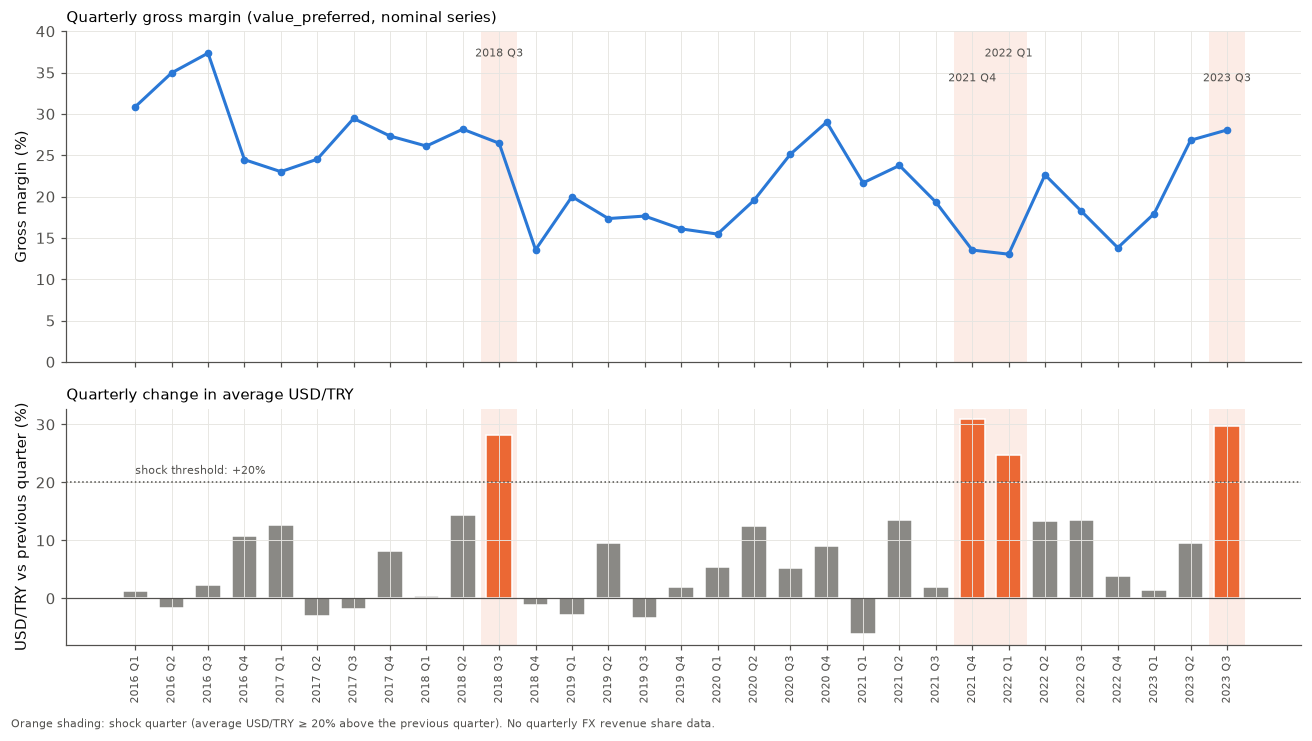

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
x = np.arange(len(qdf))
for ax in axes:
    for i in x[qdf["shock"].values]:
        ax.axvspan(i - 0.5, i + 0.5, color=C_ORANGE, alpha=0.12, linewidth=0)
ax = axes[0]
ax.plot(x, qdf["gm_pct"], marker="o", markersize=4, color=C_BLUE)
ax.set_ylabel("Gross margin (%)")
ax.set_ylim(0, 40)
ax.set_title("Quarterly gross margin (value_preferred, nominal series)", loc="left", fontsize=10)
for k, i in enumerate(x[qdf["shock"].values]):
    ax.text(i, 38 - 3 * (k % 2), qdf.loc[i, "label"], ha="center", va="top", fontsize=7.5, color=C_MUTED)  # adjacent labels are offset
ax = axes[1]
ax.bar(x, qdf["usd_try_qoq_pct"], width=0.7, color=[C_ORANGE if s else C_GREY for s in qdf["shock"]], edgecolor="white", linewidth=1)
ax.axhline(20, color=C_MUTED, linestyle=":", linewidth=1)
ax.text(0, 21, "shock threshold: +20%", fontsize=7.5, color=C_MUTED, va="bottom")
ax.axhline(0, color=C_MUTED, linewidth=0.8)
ax.set_ylabel("USD/TRY vs previous quarter (%)")
ax.set_title("Quarterly change in average USD/TRY", loc="left", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(qdf["label"], rotation=90, fontsize=7)
fig.text(0.01, -0.01, "Orange shading: shock quarter (average USD/TRY ≥ 20% above the previous quarter). No quarterly FX revenue share data.",
         fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "03_fx_shocks_quarterly_margin.png", bbox_inches="tight")
plt.show()

In [7]:
idx = sorted(set(i for i in qdf.index[qdf["shock"]] for i in (i, i + 1) if i < len(qdf)))
shock_tbl = qdf.loc[idx, ["label", "usd_try_qoq_pct", "gm_pct", "d_qoq", "d_yoy", "d_vs_prev4"]].copy()
shock_tbl["role"] = ["shock" if qdf.loc[i, "shock"] else "post-shock" for i in idx]
shock_tbl["annual_export_share_pct"] = [own.loc[qdf.loc[i, "year"], "export_share"] * 100 for i in idx]
shock_tbl.set_index("label").round(1)

,usd_try_qoq_pct,gm_pct,d_qoq,d_yoy,d_vs_prev4,role,annual_export_share_pct
label,,,,,,,
2018 Q3,28.1,26.5,-1.7,-3.0,-1.3,shock,44.6
2018 Q4,-1.2,13.6,-12.9,-13.8,-13.4,post-shock,44.6
2021 Q4,30.9,13.5,-5.8,-15.5,-9.9,shock,56.2
2022 Q1,24.8,13.0,-0.5,-8.6,-6.5,shock,49.5
2022 Q2,13.3,22.6,9.6,-1.1,5.2,post-shock,49.5
2023 Q3,29.7,28.1,1.2,9.8,8.9,shock,39.1


**What we see:**
- **2018:** In the shock quarter (Q3) the gross margin is 26.5%. That is −1.7 points versus the previous quarter and −3.0 points versus the same quarter of the previous year. The real decline comes in the quarter after the shock: in 2018 Q4 the margin is 13.6%, −13.8 points versus the same quarter of the previous year.
- **2021–22:** The margin is 13.5% in 2021 Q4 and 13.0% in 2022 Q1. That is −15.5 and −8.6 points versus the same quarters of the previous year.
- **2023 Q3:** In this quarter, by contrast, the margin is +9.8 points above the same quarter of the previous year.
- **Reading:** In the 2018 and 2021–22 shocks, when the annual FX revenue share was 45–57%, the gross margin fell clearly in the shock quarter or the following quarter. There are FX-linked items on the cost side too (energy; notebook 01). FX revenue was not enough to prevent the margin from falling in shock quarters; without a peer company, how the margin would have developed without FX revenue cannot be known. How much is due to FX and how much to energy prices or demand cannot be separated with this data; 2021 Q4 – 2022 Q1 also coincides with the energy price shock.

## 3. Debt structure: loans by currency (2016–2025)

Source: breakdown of loans in the borrowings note (`fx_debt_annual.csv`; excluding lease liabilities). The year's own report is used. Dollar equivalents are calculated at the EVDS year-end rate. Because TRY amounts cannot be compared between the nominal and IAS 29 series, the chart shows dollar equivalents and shares.

Note: For three "USD" loan lines in the 2024 report the TRY/original ratio is close to the EUR rate; these lines were left with the report's label (USD) (`output/checks/fx_debt_checks.csv`).

In [8]:
debt = pd.DataFrame({
    "try_mn_try": [fxv("debt_try", y) / 1e6 for y in YEARS],
    "eur_mn_try": [fxv("debt_eur_try", y) / 1e6 for y in YEARS],
    "usd_mn_try": [fxv("debt_usd_try", y) / 1e6 for y in YEARS],
    "other_mn_try": [fxv("debt_other_try", y) / 1e6 for y in YEARS],
}, index=YEARS)
debt["total_mn_try"] = debt.sum(axis=1)
debt["fx_mn_try"] = debt[["eur_mn_try", "usd_mn_try", "other_mn_try"]].sum(axis=1)
debt["usd_try_year_end"] = usd_end.reindex(YEARS).values
for c in ["try", "eur", "usd", "other", "fx", "total"]:
    debt[f"{c}_mn_usd"] = debt[f"{c}_mn_try"] / debt["usd_try_year_end"]
for c in ["try", "eur", "usd", "other"]:
    debt[f"{c}_share_pct"] = debt[f"{c}_mn_try"] / debt["total_mn_try"] * 100
debt["fx_share_pct"] = debt["fx_mn_try"] / debt["total_mn_try"] * 100
debt["basis"] = own["basis"]
debt.round(1)

,try_mn_try,eur_mn_try,usd_mn_try,other_mn_try,total_mn_try,fx_mn_try,usd_try_year_end,try_mn_usd,eur_mn_usd,usd_mn_usd,other_mn_usd,fx_mn_usd,total_mn_usd,try_share_pct,eur_share_pct,usd_share_pct,other_share_pct,fx_share_pct,basis
2016,667.8,73.4,45.7,0.0,787.0,119.2,3.5,189.1,20.8,13.0,0.0,33.7,222.8,84.9,9.3,5.8,0.0,15.1,nominal
2017,932.0,358.1,86.8,0.0,1376.8,444.8,3.8,244.6,94.0,22.8,0.0,116.7,361.3,67.7,26.0,6.3,0.0,32.3,nominal
2018,755.3,510.7,214.5,0.0,1480.5,725.2,5.3,143.6,97.1,40.8,0.0,137.8,281.4,51.0,34.5,14.5,0.0,49.0,nominal
2019,789.7,458.9,403.6,0.0,1652.2,862.5,5.9,132.9,77.3,67.9,0.0,145.2,278.1,47.8,27.8,24.4,0.0,52.2,nominal
2020,720.6,757.3,44.8,0.0,1522.7,802.1,7.3,98.2,103.2,6.1,0.0,109.3,207.4,47.3,49.7,2.9,0.0,52.7,nominal
2021,455.6,855.0,0.0,0.0,1310.6,855.0,13.0,35.1,65.9,0.0,0.0,65.9,101.0,34.8,65.2,0.0,0.0,65.2,nominal
2022,1674.9,1094.4,0.0,0.0,2769.3,1094.4,18.7,89.6,58.5,0.0,0.0,58.5,148.1,60.5,39.5,0.0,0.0,39.5,nominal
2023,2768.2,4009.8,1394.8,66.3,8239.0,5470.8,29.4,94.2,136.4,47.4,2.3,186.1,280.3,33.6,48.7,16.9,0.8,66.4,tms29
2024,2696.6,14152.0,3989.1,72.7,20910.4,18213.7,35.2,76.6,401.8,113.3,2.1,517.1,593.7,12.9,67.7,19.1,0.3,87.1,tms29
2025,3610.9,18613.3,5641.4,102.1,27967.8,24356.9,42.9,84.2,434.3,131.6,2.4,568.3,652.5,12.9,66.6,20.2,0.4,87.1,tms29


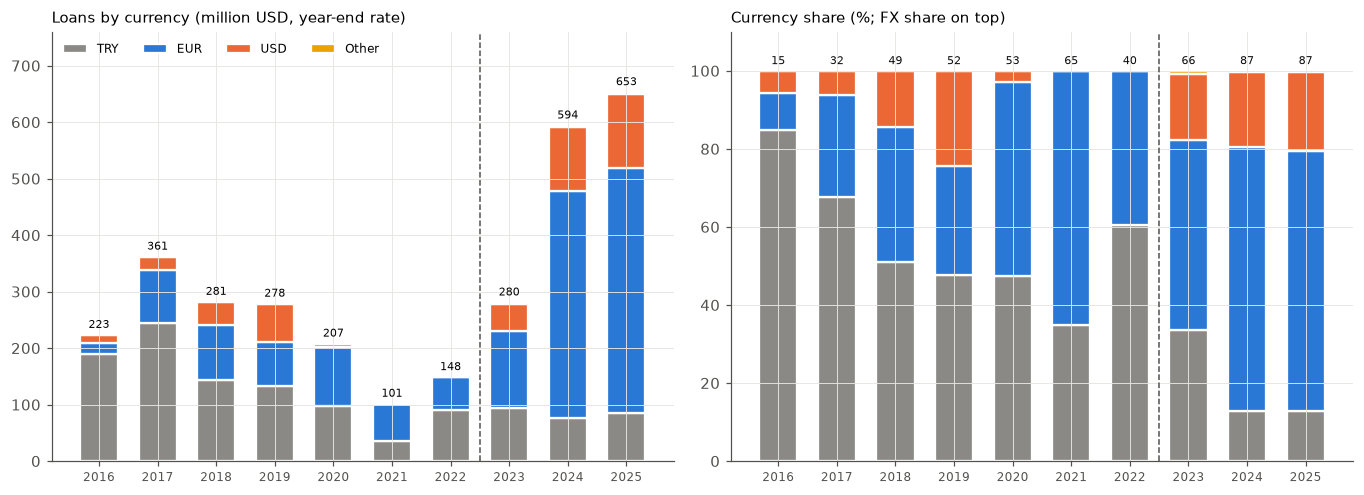

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
CUR = [("try", "TRY", C_GREY), ("eur", "EUR", C_BLUE), ("usd", "USD", C_ORANGE), ("other", "Other", C_YELLOW)]
ax = axes[0]
bottom = np.zeros(len(YEARS))
for c, lab, col in CUR:
    v = debt[f"{c}_mn_usd"].values
    ax.bar(YEARS, v, bottom=bottom, color=col, width=0.65, edgecolor="white", linewidth=1.5, label=lab)
    bottom += v
for y, t in zip(YEARS, bottom):
    ax.text(y, t + 8, f"{t:.0f}", ha="center", va="bottom", fontsize=7.5)
ax.set_title("Loans by currency (million USD, year-end rate)", loc="left", fontsize=10)
ax.legend(loc="upper left", fontsize=8, ncol=4)
ax.set_ylim(0, 760)
ax = axes[1]
bottom = np.zeros(len(YEARS))
for c, lab, col in CUR:
    v = debt[f"{c}_share_pct"].values
    ax.bar(YEARS, v, bottom=bottom, color=col, width=0.65, edgecolor="white", linewidth=1.5, label=lab)
    bottom += v
for y, v in debt["fx_share_pct"].items():
    ax.text(y, 101, f"{v:.0f}", ha="center", va="bottom", fontsize=7.5, color=C_INK)
ax.set_title("Currency share (%; FX share on top)", loc="left", fontsize=10)
ax.set_ylim(0, 110)
for ax in axes:
    ax.set_xticks(YEARS); ax.tick_params(axis="x", labelsize=8)
    ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
fig.tight_layout()
fig.savefig(FIGS / "03_debt_by_currency.png", bbox_inches="tight")
plt.show()

**What we see:**
- The share of FX loans in total loans is 15% in 2016. ~50% in 2018–2020, 65% in 2021, 40% in 2022. 66% in 2023, 87% in 2024–2025.
- Total loans in dollars are in the ~100–360 million USD band in 2016–2022. ~590 in 2024, ~650 million USD in 2025; most of the increase is in EUR loans (2025: ~434 million USD equivalent).
- The jump in 2024 coincides with the Mannok acquisition (consolidated from 1 October 2024).

## 4. Coverage ratios

### 4a. Group view (main)

- **FX loans / export sales:** FX loans (EUR + USD + other) are converted to dollars at the year-end rate; export sales are converted (average in nominal years, year-end rate in IAS 29 years). The ratio shows how many years of export sales the FX debt equals.
- **FX loans / EBITDA proxy:** EBITDA proxy (operating profit + depreciation) in dollars via `ebitda_proxy_usd`. Not the reported EBITDA.

**Limits:**
- In 2024 only Mannok's Q4 sales and profit were consolidated, but the acquisition-related debt is fully included in the year-end balance. 2024 ratios may therefore be biased upwards; they are marked in the chart. **The main post-transformation year is 2025.**
- **IAS 29 years:** Dollar amounts are converted at the year-end rate and may be slightly biased upwards.

In [10]:
cov = pd.DataFrame({
    "fx_loans_mn_usd": debt["fx_mn_usd"],
    "export_sales_mn_usd": own["revenue_export"] / own["usd_try_rate_used"] / 1e6,
    "ebitda_proxy_mn_usd": own["ebitda_proxy_usd"] / 1e6,
    "export_rate_basis": own["usd_rate_basis"],
})
cov["fx_loans_to_export_sales"] = cov["fx_loans_mn_usd"] / cov["export_sales_mn_usd"]
cov["fx_loans_to_ebitda_proxy"] = cov["fx_loans_mn_usd"] / cov["ebitda_proxy_mn_usd"]
cov.round(2)

,fx_loans_mn_usd,export_sales_mn_usd,ebitda_proxy_mn_usd,export_rate_basis,fx_loans_to_export_sales,fx_loans_to_ebitda_proxy
2016,33.74,131.08,120.70,EVDS USD/TRY 2016 annual average,0.26,0.28
2017,116.74,153.96,112.81,EVDS USD/TRY 2017 annual average,0.76,1.03
2018,137.84,181.00,88.42,EVDS USD/TRY 2018 annual average,0.76,1.56
2019,145.20,202.25,54.09,EVDS USD/TRY 2019 annual average,0.72,2.68
2020,109.26,164.21,70.66,EVDS USD/TRY 2020 annual average,0.67,1.55
2021,65.89,259.37,98.60,EVDS USD/TRY 2021 annual average,0.25,0.67
2022,58.53,287.21,87.96,EVDS USD/TRY 2022 annual average,0.20,0.67
2023,186.10,293.86,153.19,EVDS USD/TRY 2023 year-end (IAS 29: purchasing...,0.63,1.21
2024,517.09,477.46,156.31,EVDS USD/TRY 2024 year-end (IAS 29: purchasing...,1.08,3.31
2025,568.26,756.33,212.32,EVDS USD/TRY 2025 year-end (IAS 29: purchasing...,0.75,2.68


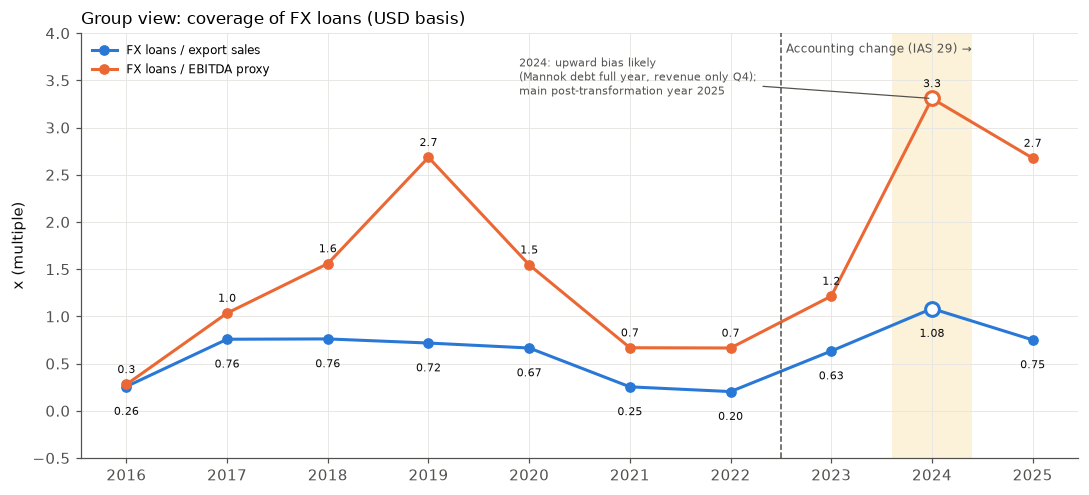

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(YEARS, cov["fx_loans_to_export_sales"], marker="o", color=C_BLUE, label="FX loans / export sales")
ax.plot(YEARS, cov["fx_loans_to_ebitda_proxy"], marker="o", color=C_ORANGE, label="FX loans / EBITDA proxy")
for y in YEARS:
    ax.text(y, cov.loc[y, "fx_loans_to_ebitda_proxy"] + 0.12, f"{cov.loc[y, 'fx_loans_to_ebitda_proxy']:.1f}", ha="center", fontsize=7.5, color=C_INK)
    ax.text(y, cov.loc[y, "fx_loans_to_export_sales"] - 0.3, f"{cov.loc[y, 'fx_loans_to_export_sales']:.2f}", ha="center", fontsize=7.5, color=C_INK)
ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
ax.text(2022.55, 3.9, "Accounting change (IAS 29) →", fontsize=8, color=C_MUTED, va="top")
ax.axvspan(2023.6, 2024.4, color=C_YELLOW, alpha=0.15, linewidth=0)
for col, c in [("fx_loans_to_export_sales", C_BLUE), ("fx_loans_to_ebitda_proxy", C_ORANGE)]:
    ax.plot(2024, cov.loc[2024, col], marker="o", markersize=9, markerfacecolor="white", markeredgecolor=c, markeredgewidth=2, linestyle="none")
ax.annotate("2024: upward bias likely\n(Mannok debt full year, revenue only Q4);\nmain post-transformation year 2025", (2024, cov.loc[2024, "fx_loans_to_ebitda_proxy"]),
            xytext=(2019.9, 3.35), fontsize=7.5, color=C_MUTED, arrowprops=dict(arrowstyle="-", color=C_MUTED, linewidth=0.8))
ax.set_xticks(YEARS)
ax.set_ylim(-0.5, 4)
ax.set_ylabel("x (multiple)")
ax.set_title("Group view: coverage of FX loans (USD basis)", loc="left", fontsize=11)
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "03_group_fx_debt_coverage.png", bbox_inches="tight")
plt.show()

**What we see:**
- **Coverage by export sales:** FX loans are 0.26 times annual export sales in 2016. 0.67–0.76 in 2017–2020, 0.20–0.25 times in 2021–2022. 1.08 in 2024, 0.75 times in 2025.
- **Coverage by the EBITDA proxy:** 0.3 in 2016, 2.7 in 2019, 0.7 in 2021–2022, 3.3 in 2024, 2.7 times in 2025.
- **Reading:** FX debt grew markedly after 2023. Because export sales also grew (including subsidiaries abroad from 2024), the coverage by sales is close to the 2017–2020 level. Relative to EBITDA, however, FX debt in 2025 is at the same level as the 2019 peak (2.7x) and about four times that of 2021–2022 (0.7x).

### 4b. Turkey view (supplementary): net FX position (main indicator) and 10% FX sensitivity (secondary)

**Scope:** The effects of exchange rate changes note covers only companies with TRY functional currency ("the national currencies of subsidiaries abroad are not included in the foreign currency position").

**Choice of source:**
- Default: the year's own report.
- **2018:** The net position is taken from the comparative value in the 2019 report. In the 2018 own report FX financial liabilities are shown equal to total financial debt; the net position of −TRY 1.04 billion is probably wrong.
- **2023:** Derivatives and net position are taken from the comparative value in the 2024 report. In its own report the derivative position is shown as positive, but the net position is reached by subtracting it. Because the 2023 TRY amounts in the 2024 report are in December 2024 purchasing power, they are pulled back to December 2023 purchasing power using the ratio of total FX assets reported in both reports (2024 report / 2023 report ≈ 1.44). USD and EUR original amounts are not indexed, so they are taken directly.

**Indicator priority:** The main indicator is the net FX position. The 10% FX sensitivity is secondary because in 2023–2024 it is disproportionate to the net position due to intra-group loans.

**Sensitivity:** The reported value is used; effect on profit/loss in the case of a 10% appreciation of foreign currency.
- According to the note text, the analysis also covers loans used for intra-group foreign operations that are in currencies other than the parties' functional currencies. Indeed, in 2016, 2019–2022 and 2025 the sensitivity is exactly 10% of the net position; 16% in 2017, and much larger in 2023–2024.
- **2018:** The main value is the comparative value in the 2019 report (+TRY 1.9 million). This is consistent with the net position decision and exactly 10% of the net position. The value in its own report (−TRY 28.7 million) is based on the inconsistent USD/EUR position in the same report; it is shown in a separate column.

In [12]:
SRC = {2018: 2019, 2023: 2024}
deflator_2023 = fxv("fx_assets_total_try", 2023, 2024) / fxv("fx_assets_total_try", 2023)
print(f"2023 purchasing power adjustment factor (2024 report / 2023 report, total FX assets): {deflator_2023:.4f}")

tr = pd.DataFrame(index=YEARS)
tr["source_report"] = [SRC.get(y, y) for y in YEARS]
tr["net_position_mn_try"] = [fxv("fx_net_position_try", y, SRC.get(y)) / 1e6 for y in YEARS]
tr.loc[2023, "net_position_mn_try"] /= deflator_2023
tr["derivatives_mn_try"] = [fxv("fx_derivatives_net_try", y, SRC.get(y)) / 1e6 for y in YEARS]
tr.loc[2023, "derivatives_mn_try"] /= deflator_2023
tr["net_position_usd_orig_mn"] = [fxv("fx_net_position_usd", y, SRC.get(y)) / 1e6 for y in YEARS]
tr["net_position_eur_orig_mn"] = [fxv("fx_net_position_eur", y, SRC.get(y)) / 1e6 for y in YEARS]
tr["net_position_mn_usd_equiv"] = tr["net_position_mn_try"] / usd_end.reindex(YEARS).values
tr["fx_financial_liabilities_mn_try"] = [fxv("fx_financial_liabilities_try", y, SRC.get(y)) / 1e6 for y in YEARS]
tr.loc[2023, "fx_financial_liabilities_mn_try"] /= deflator_2023
tr["sensitivity_pl_mn_try"] = [fxv("fx_sensitivity_total_pl_try", y, SRC.get(y) if y == 2018 else None) / 1e6 for y in YEARS]
tr["sensitivity_pl_own_report_mn_try"] = np.nan  # 2018: own-report value (side column)
tr.loc[2018, "sensitivity_pl_own_report_mn_try"] = fxv("fx_sensitivity_total_pl_try", 2018) / 1e6
tr["sensitivity_to_net_position"] = tr["sensitivity_pl_mn_try"] / tr["net_position_mn_try"]
tr["sensitivity_to_ebitda_pct"] = tr["sensitivity_pl_mn_try"] / (own["ebitda_proxy"] / 1e6) * 100
tr.round(3)

2023 purchasing power adjustment factor (2024 report / 2023 report, total FX assets): 1.4438


,source_report,net_position_mn_try,derivatives_mn_try,net_position_usd_orig_mn,net_position_eur_orig_mn,net_position_mn_usd_equiv,fx_financial_liabilities_mn_try,sensitivity_pl_mn_try,sensitivity_pl_own_report_mn_try,sensitivity_to_net_position,sensitivity_to_ebitda_pct
2016,2016,-110.616,0.000,-27.282,-3.928,-31.320,86.529,-11.062,NaN,0.100,-3.033
2017,2017,-3.560,249.461,-3.329,1.992,-0.934,380.261,-0.578,NaN,0.162,-0.140
2018,2019,19.023,407.081,2.042,1.023,3.616,572.579,1.902,-28.712,0.100,0.448
2019,2019,50.694,229.291,16.347,-8.051,8.534,526.184,5.069,NaN,0.100,1.653
2020,2020,25.142,189.759,25.978,-18.329,3.425,802.216,2.514,NaN,0.100,0.508
2021,2021,57.050,558.446,13.316,-8.649,4.396,855.924,5.705,NaN,0.100,0.651
2022,2022,362.238,694.984,26.772,-7.572,19.375,1110.124,36.224,NaN,0.100,2.486
2023,2024,1432.661,353.258,58.825,-16.014,48.734,2460.580,874.749,NaN,0.611,19.424
2024,2024,1635.869,6400.056,29.743,16.297,46.443,6532.678,1876.429,NaN,1.147,34.081
2025,2025,849.243,9829.219,-2.329,17.196,19.813,9829.219,84.924,NaN,0.100,0.933


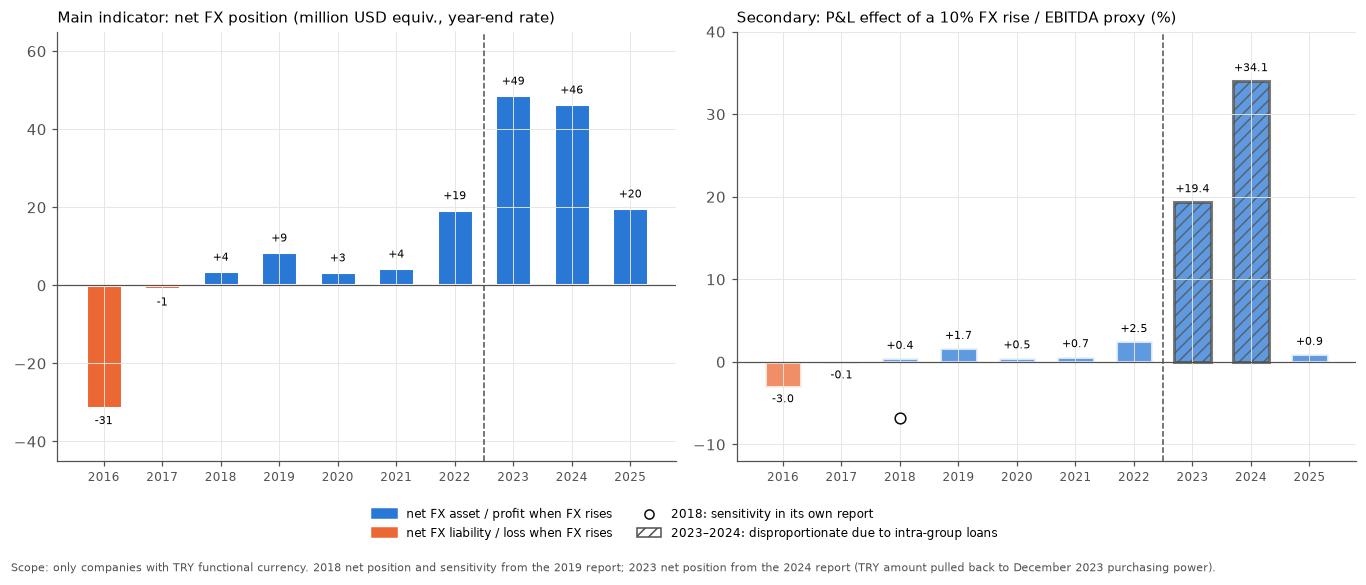

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
v = tr["net_position_mn_usd_equiv"]
ax.bar(YEARS, v, width=0.62, color=[C_BLUE if x >= 0 else C_ORANGE for x in v], edgecolor="white", linewidth=2)
for y, x in v.items():
    ax.text(y, x + (2 if x >= 0 else -2), f"{x:+.0f}", ha="center", va="bottom" if x >= 0 else "top", fontsize=7.5)
ax.axhline(0, color=C_MUTED, linewidth=0.8)
ax.set_title("Main indicator: net FX position (million USD equiv., year-end rate)", loc="left", fontsize=10)
ax.set_ylim(-45, 65)
ax = axes[1]
s = tr["sensitivity_to_ebitda_pct"]
bars = ax.bar(YEARS, s, width=0.62, color=[C_BLUE if x >= 0 else C_ORANGE for x in s], edgecolor="white", linewidth=2, alpha=0.75)
for b, y in zip(bars, YEARS):
    if y in (2023, 2024):
        b.set_hatch("///"); b.set_edgecolor(C_MUTED)
for y, x in s.items():
    ax.text(y, x + (0.8 if x >= 0 else -0.8), f"{x:+.1f}", ha="center", va="bottom" if x >= 0 else "top", fontsize=7.5)
ax.plot(2018, tr.loc[2018, "sensitivity_pl_own_report_mn_try"] / (own.loc[2018, "ebitda_proxy"] / 1e6) * 100, marker="o", markersize=7,
        markerfacecolor="white", markeredgecolor=C_INK, linestyle="none")
ax.axhline(0, color=C_MUTED, linewidth=0.8)
ax.set_title("Secondary: P&L effect of a 10% FX rise / EBITDA proxy (%)", loc="left", fontsize=10)
ax.set_ylim(-12, 40)
for ax in axes:
    ax.set_xticks(YEARS); ax.tick_params(axis="x", labelsize=8)
    ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
fig.legend(handles=[Patch(color=C_BLUE, label="net FX asset / profit when FX rises"),
                    Patch(color=C_ORANGE, label="net FX liability / loss when FX rises"),
                    Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor=C_INK, linestyle="none",
                           label="2018: sensitivity in its own report"),
                    Patch(facecolor="white", edgecolor=C_MUTED, hatch="///", label="2023–2024: disproportionate due to intra-group loans")],
           loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.1))
fig.text(0.01, -0.14, "Scope: only companies with TRY functional currency. 2018 net position and sensitivity from the 2019 report; 2023 net position from the 2024 report "
         "(TRY amount pulled back to December 2023 purchasing power).", fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "03_turkey_fx_position_sensitivity.png", bbox_inches="tight")
plt.show()

**What we see:**
- **2016:** The net FX position of the companies in Turkey is −31 million USD equivalent (net liability).
- **2017–2022:** The position is between −1 and +19 million USD, close to zero or a slight net asset.
- **2023–2025:** +49, +46 and +20 million USD; net asset. In this period derivatives (off-balance-sheet positions covering most of the FX financial liabilities) are decisive: in 2025 the derivative position equals FX financial liabilities.
- **Sensitivity (secondary):** The P&L effect of a 10% FX rise is −3.0% of the EBITDA proxy in 2016 (loss), between +0.4% and +2.5% in 2018–2022 (profit), and +0.9% in 2025.
- **2023–2024 sensitivity:** +19% and +34%, i.e. 6–11 times 10% of the net position. This is related to the analysis also covering intra-group loans; these two years are not used in the main interpretation.
- **Reading:** From 2017 the balance sheet of the companies in Turkey is either balanced or in a net asset position against an FX rise. Where FX debt has really grown is outside this view, i.e. in the subsidiaries abroad (4a).

## 5. Interim findings and assessment of H1

**Section summaries**
1. **FX revenue share:** 31% (2016) → 45–57% (2018–2021) → 64% (2025). From 2024 it also includes sales of subsidiaries abroad.
2. **FX shocks:** In the 2018 and 2021–22 shocks the quarterly gross margin fell by 9–16 points versus the same quarter of the previous year, in the shock quarter or the following quarter. Over the same period the annual FX revenue share was 45–57%.
3. **Debt structure:** The share of FX loans rose from 15% (2016) to 87% (2024–2025). Total loans in dollars rose from ~150 million USD in 2022 to ~650 million USD in 2025 (~4.4 times); the increase is mainly in EUR.
4. **Coverage (group):** FX loans / export sales is 0.75x in 2025, close to the 2017–2020 level. FX loans / EBITDA proxy is 2.7x in 2025, clearly above the 0.7x of 2021–2022.
5. **Turkey view (main indicator: net position):** The net FX position has been balanced or a net asset since 2017. Derivatives cover most of the FX financial liabilities.

**Assessment of H1: PARTIALLY (the first half is not supported as far as it can be measured, the second half is partly confirmed)**
- *"The export sales share protected the gross margin during FX shocks":* **Not supported (as far as it can be measured).**
  - In the 2018 and 2021–22 shocks the quarterly gross margin fell clearly while the FX revenue share was high.
  - FX revenue was not enough to prevent the margin from falling in shock quarters; without a peer company, how the margin would have developed without FX revenue cannot be known.
  - On the cost side, FX-linked items (energy) also rose over the same period.
  - Limits: Without quarterly FX revenue share data, it cannot be shown how the revenue mix changed in shock quarters. FX, energy price and demand effects cannot be separated with this data.
- *"FX debt rose, the protection was partly offset on the balance sheet":* **Partly confirmed.**
  - FX debt rose markedly (FX share 87%; 2.7x EBITDA).
  - However, the net FX position of the companies in Turkey is hedged with derivatives or a net asset.
  - Most of the FX debt sits in subsidiaries abroad whose revenue is in the same currency (e.g. EUR debt – EUR revenue). At group level FX loans are 0.75x export sales.
  - So the risk is not an "FX gap on the TRY balance sheet" but the "debt-carrying capacity of the foreign operations".

**Points to carry over to H4 (synthesis)**
- **Leverage level:** FX loans / EBITDA proxy 2.7x (2025). To be considered together with net debt / EBITDA.
- **Where the FX risk sits:** FX risk on the Turkish balance sheet is limited (derivatives, net asset). The quality of group-level FX debt depends on the cash flow of the subsidiaries abroad (Mannok, SBS).
- **Margin in shocks:** FX revenue was not enough to prevent the margin from falling in shock quarters; without a peer company, how the margin would have developed without FX revenue cannot be known. Resilience should be sought at most at the balance sheet level, not at the margin level.
- **Common pattern (notebook 01):** Energy price smoothing does not remove the burden of the shock; it spreads it over time. This pattern should be assessed together in the margin volatility analysis (04).
- **Data limits:**
  - 2024 ratios include only Mannok's Q4 revenue (upward bias likely); main post-transformation year 2025.
  - The 2023–2024 FX sensitivity is disproportionate to the net position.
  - For the 2018 sensitivity the main value is from the 2019 report (the own report differs and is inconsistent).
  - No quarterly FX revenue share.